In [1]:
!git clone https://github.com/JoaoPioltini/template_matching.git
%cd template_matching
!pip install -r requirements.txt

Cloning into 'template_matching'...
remote: Enumerating objects: 24, done.
remote: Counting objects: 100% (24/24), done.
remote: Compressing objects: 100% (22/22), done.
remote: Total 24 (delta 6), reused 13 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (24/24), 434.13 KiB | 1.77 MiB/s, done.
Resolving deltas: 100% (6/6), done.
/content/template_matching


Dimensões: (777, 735, 3)


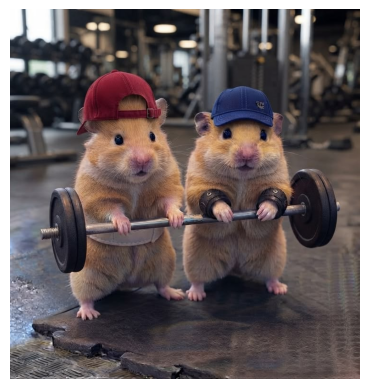

In [2]:
import cv2
import matplotlib.pyplot as plt

imagem = cv2.imread("image2.jpg")

print("Dimensões:", imagem.shape)

plt.imshow(cv2.cvtColor(imagem, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

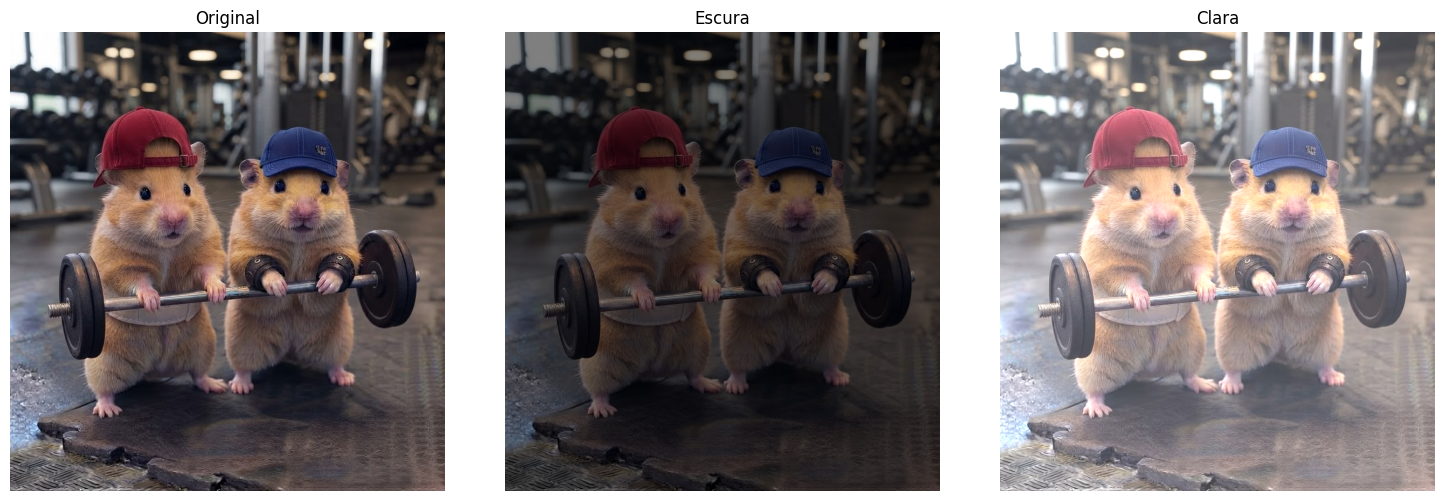

In [3]:
import cv2
import matplotlib.pyplot as plt

# Criar versões com diferentes iluminações
escura = cv2.convertScaleAbs(imagem, alpha=0.5, beta=0)
clara = cv2.convertScaleAbs(imagem, alpha=1.0, beta=70)

# Mostrar as três imagens
fig, ax = plt.subplots(1, 3, figsize=(15, 5))

imagens = [imagem, escura, clara]
titulos = ["Original", "Escura", "Clara"]

for i in range(3):
    ax[i].imshow(cv2.cvtColor(imagens[i], cv2.COLOR_BGR2RGB))
    ax[i].set_title(titulos[i])
    ax[i].axis("off")

plt.tight_layout()
plt.show()

Original: 1.0000 | Posição: (375, 165)
Escura: 0.9999 | Posição: (375, 165)
Clara: 0.9991 | Posição: (375, 165)


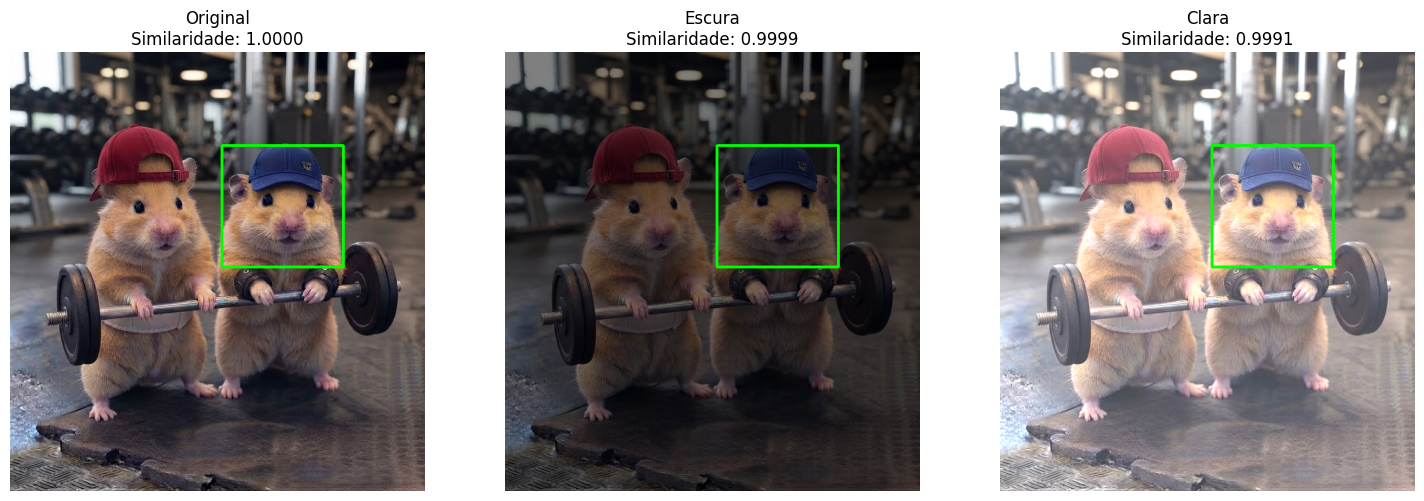

In [4]:
import cv2
import matplotlib.pyplot as plt

# Template de referência do projeto
template = cv2.imread("exemplo/template_hamster.png")

if template is None:
    raise ValueError("Template não encontrado")

# Converter o template para escala de cinza
template_cinza = cv2.cvtColor(template, cv2.COLOR_BGR2GRAY)
h, w = template_cinza.shape

fig, ax = plt.subplots(1, 3, figsize=(15, 5))

for i, (nome, img) in enumerate(zip(titulos, imagens)):

    cinza = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # Executar Template Matching
    resultado = cv2.matchTemplate(
        cinza,
        template_cinza,
        cv2.TM_CCOEFF_NORMED
    )

    _, pontuacao, _, posicao = cv2.minMaxLoc(resultado)

    # Desenhar retângulo na região encontrada
    saida = img.copy()
    x, y = posicao

    if pontuacao >= 0.8:
        cv2.rectangle(
            saida,
            (x, y),
            (x + w, y + h),
            (0, 255, 0),
            3
        )

    ax[i].imshow(cv2.cvtColor(saida, cv2.COLOR_BGR2RGB))
    ax[i].set_title(f"{nome}\nSimilaridade: {pontuacao:.4f}")
    ax[i].axis("off")

    print(f"{nome}: {pontuacao:.4f} | Posição: {posicao}")

plt.tight_layout()
plt.show()

### Experimento 1 — Variação de iluminação

O primeiro experimento teve como objetivo avaliar o comportamento do algoritmo Template Matching diante de diferentes condições de iluminação.

Foram utilizadas três versões da mesma imagem: original, com redução de brilho e com aumento de brilho. O método de comparação utilizado foi o `TM_CCOEFF_NORMED`, disponibilizado pela biblioteca OpenCV.

Os resultados obtidos foram:

| Condição | Similaridade | Posição detectada |
|---|---|---|
| Original | 1,0000 | (375, 165) |
| Escura | 0,9999 | (375, 165) |
| Clara | 0,9991 | (375, 165) |

Observou-se que o algoritmo conseguiu localizar corretamente o objeto nas três condições, apresentando pontuações de similaridade próximas de 1,0.

Os resultados indicam que, nas condições avaliadas, o método apresentou baixa sensibilidade às alterações globais de iluminação. Entretanto, isso não garante o mesmo desempenho em situações com sombras intensas, reflexos ou mudanças de iluminação localizadas.

Escala 0.7x: 0.6558
Escala 1.0x: 1.0000
Escala 1.3x: 0.6024


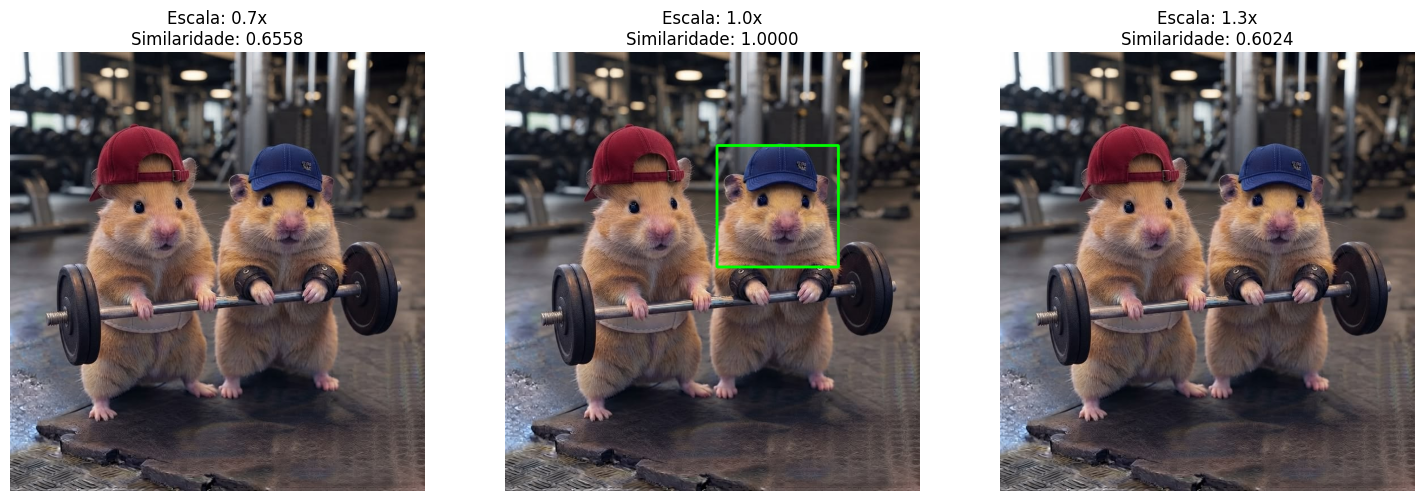

In [5]:
import cv2
import matplotlib.pyplot as plt

# Criar versões com escalas diferentes
escalas = [0.7, 1.0, 1.3]

fig, ax = plt.subplots(1, 3, figsize=(15, 5))

for i, escala in enumerate(escalas):
    # Redimensionar o template
    novo_template = cv2.resize(
        template_cinza,
        None,
        fx=escala,
        fy=escala
    )

    # Comparar com a imagem original
    resultado = cv2.matchTemplate(
        cv2.cvtColor(imagem, cv2.COLOR_BGR2GRAY),
        novo_template,
        cv2.TM_CCOEFF_NORMED
    )

    _, pontuacao, _, posicao = cv2.minMaxLoc(resultado)

    saida = imagem.copy()
    x, y = posicao
    h, w = novo_template.shape

    if pontuacao >= 0.8:
        cv2.rectangle(
            saida, (x, y),
            (x + w, y + h),
            (0, 255, 0), 3
        )

    ax[i].imshow(cv2.cvtColor(saida, cv2.COLOR_BGR2RGB))
    ax[i].set_title(
        f"Escala: {escala}x\nSimilaridade: {pontuacao:.4f}"
    )
    ax[i].axis("off")

    print(f"Escala {escala}x: {pontuacao:.4f}")

plt.tight_layout()
plt.show()

### Experimento 2 — Variação de escala

O segundo experimento teve como objetivo avaliar a influência da alteração de escala na identificação de objetos utilizando Template Matching.

Foram utilizadas três versões do template original, com escalas de 70%, 100% e 130%, mantendo a imagem de busca sem alterações. O método de comparação utilizado foi o `TM_CCOEFF_NORMED`, com limiar de detecção de 0,8.

Os resultados obtidos foram:

| Escala | Similaridade | Detecção |
|---|---|---|
| 70% | 0,6558 | Não |
| 100% | 1,0000 | Sim |
| 130% | 0,6024 | Não |

Observou-se que o algoritmo apresentou correspondência máxima quando o template manteve suas dimensões originais. Entretanto, ao reduzir ou aumentar o tamanho do template, a pontuação de similaridade diminuiu significativamente, ficando abaixo do limiar estabelecido.

Esses resultados demonstram uma limitação do Template Matching tradicional, pois o algoritmo não adapta automaticamente o tamanho do objeto durante a busca. Uma alternativa seria utilizar uma abordagem multiescala, comparando diferentes tamanhos do template para encontrar a melhor correspondência.

Rotação 0°: 1.0000
Rotação 15°: 0.6820
Rotação 30°: 0.5740
Rotação 45°: 0.5317


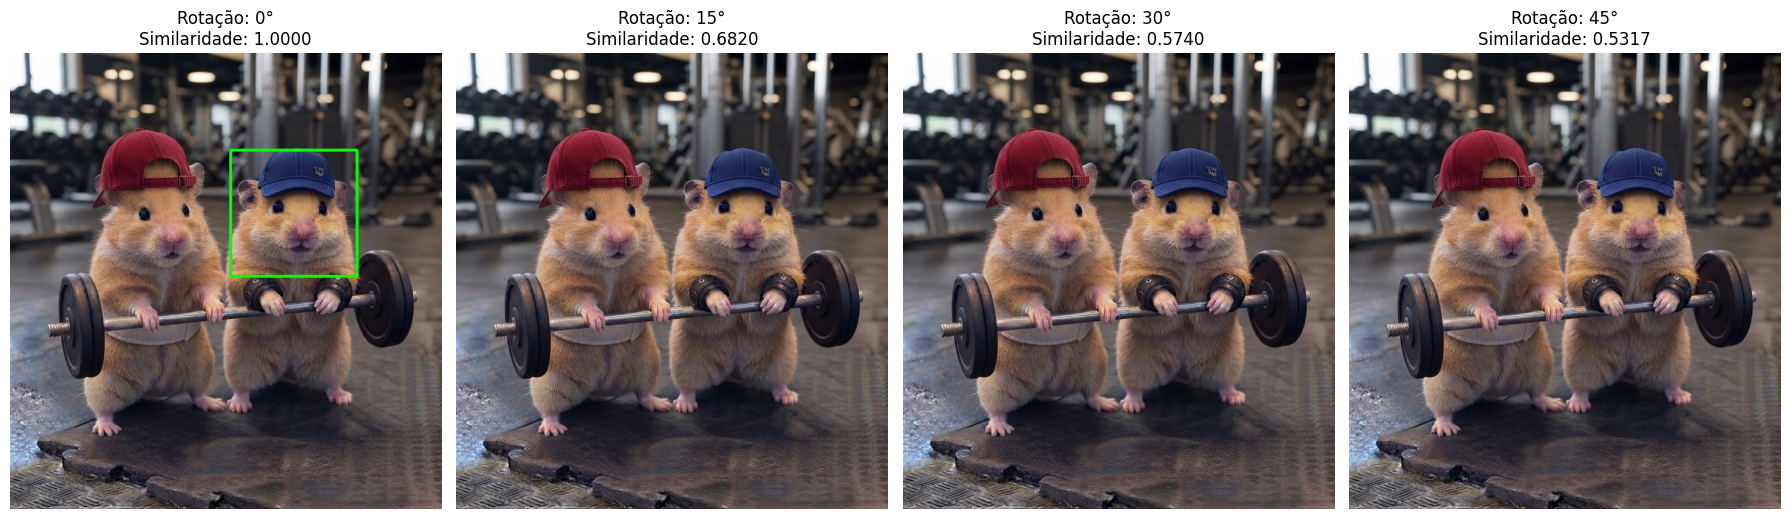

In [6]:
import cv2
import matplotlib.pyplot as plt

angulos = [0, 15, 30, 45]
imagem_cinza = cv2.cvtColor(imagem, cv2.COLOR_BGR2GRAY)

fig, ax = plt.subplots(1, 4, figsize=(18, 5))

for i, angulo in enumerate(angulos):
    h, w = template_cinza.shape

    centro = (w / 2, h / 2)

    matriz = cv2.getRotationMatrix2D(
        centro, angulo, 1.0
    )

    template_rotacionado = cv2.warpAffine(
        template_cinza,
        matriz,
        (w, h),
        borderMode=cv2.BORDER_REFLECT
    )

    resultado = cv2.matchTemplate(
        imagem_cinza,
        template_rotacionado,
        cv2.TM_CCOEFF_NORMED
    )

    _, pontuacao, _, posicao = cv2.minMaxLoc(resultado)

    saida = imagem.copy()
    x, y = posicao

    if pontuacao >= 0.8:
        cv2.rectangle(
            saida, (x, y),
            (x + w, y + h),
            (0, 255, 0), 3
        )

    ax[i].imshow(cv2.cvtColor(saida, cv2.COLOR_BGR2RGB))
    ax[i].set_title(
        f"Rotação: {angulo}°\nSimilaridade: {pontuacao:.4f}"
    )
    ax[i].axis("off")

    print(f"Rotação {angulo}°: {pontuacao:.4f}")

plt.tight_layout()
plt.show()

### Experimento 3 — Variação de rotação

O terceiro experimento teve como objetivo avaliar a influência da rotação do template na identificação do objeto.

Foram utilizados quatro ângulos de rotação: 0°, 15°, 30° e 45°, mantendo a imagem original sem alterações. O método de comparação utilizado foi o `TM_CCOEFF_NORMED`, com limiar de detecção de 0,8.

Os resultados obtidos foram:

| Rotação | Similaridade | Detecção |
|---|---|---|
| 0° | 1,0000 | Sim |
| 15° | 0,6820 | Não |
| 30° | 0,5740 | Não |
| 45° | 0,5317 | Não |

Observou-se que a similaridade diminuiu conforme o ângulo de rotação aumentou. Apenas o template sem rotação apresentou pontuação superior ao limiar estabelecido.

Os resultados indicam que o Template Matching tradicional apresenta limitações diante de alterações na orientação do objeto. Isso ocorre porque a técnica não realiza automaticamente a compensação de rotação durante a comparação.

Além disso, o procedimento utilizado manteve as dimensões originais do template, podendo provocar cortes e alterações nas bordas durante a rotação.

Uma possível alternativa para superar essa limitação seria realizar comparações com múltiplas versões rotacionadas do template.

Ruído 0: 1.0000 | Posição: (375, 165)
Ruído 15: 0.9781 | Posição: (375, 165)
Ruído 35: 0.8986 | Posição: (375, 165)
Ruído 60: 0.7647 | Posição: (375, 165)


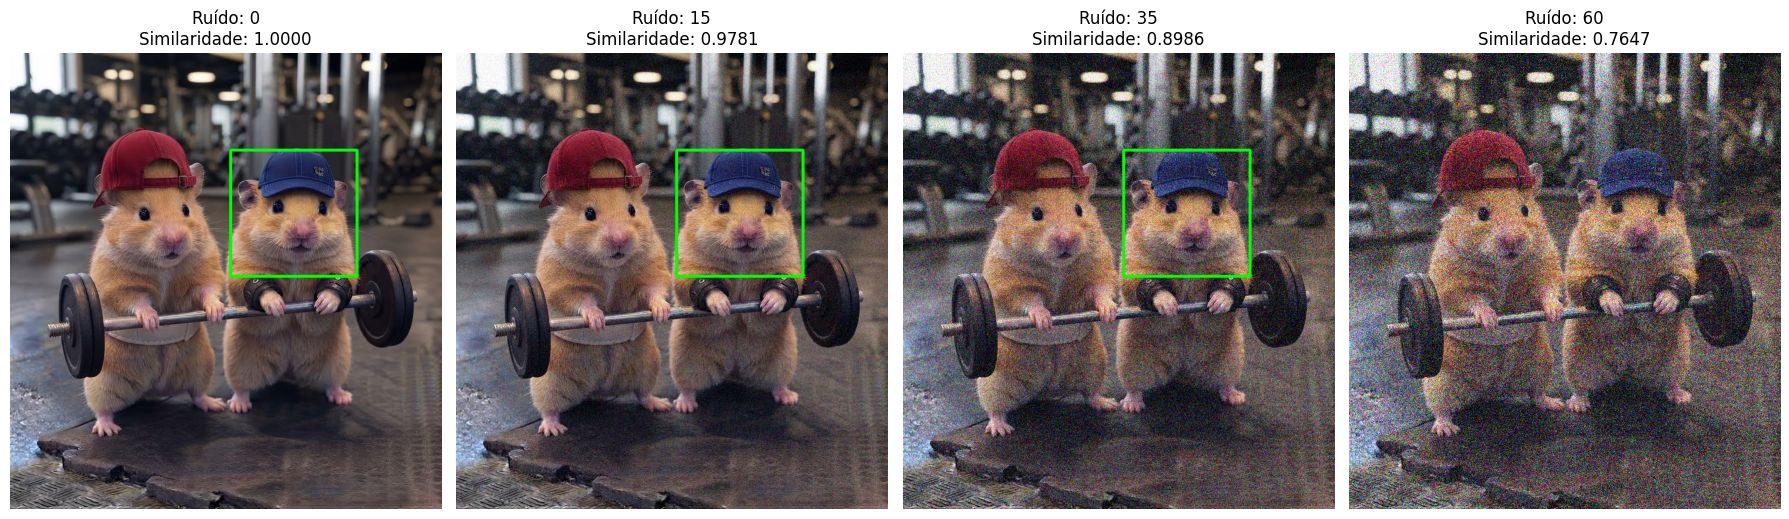

In [7]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Gerador aleatório reproduzível
rng = np.random.default_rng(42)

# Diferentes intensidades de ruído gaussiano
niveis = [0, 15, 35, 60]
fig, ax = plt.subplots(1, 4, figsize=(18, 5))

for i, nivel in enumerate(niveis):
    ruido = rng.normal(0, nivel, imagem.shape)

    imagem_ruido = np.clip(
        imagem.astype(np.float32) + ruido,
        0, 255
    ).astype(np.uint8)

    cinza = cv2.cvtColor(imagem_ruido, cv2.COLOR_BGR2GRAY)

    resultado = cv2.matchTemplate(
        cinza,
        template_cinza,
        cv2.TM_CCOEFF_NORMED
    )

    _, pontuacao, _, posicao = cv2.minMaxLoc(resultado)

    saida = imagem_ruido.copy()
    x, y = posicao
    h, w = template_cinza.shape

    if pontuacao >= 0.8:
        cv2.rectangle(
            saida, (x, y),
            (x + w, y + h),
            (0, 255, 0), 3
        )

    ax[i].imshow(cv2.cvtColor(saida, cv2.COLOR_BGR2RGB))
    ax[i].set_title(
        f"Ruído: {nivel}\nSimilaridade: {pontuacao:.4f}"
    )
    ax[i].axis("off")

    print(f"Ruído {nivel}: {pontuacao:.4f} | Posição: {posicao}")

plt.tight_layout()
plt.show()

### Experimento 4 — Influência do ruído

O quarto experimento teve como objetivo avaliar a resistência do algoritmo Template Matching diante da presença de ruído na imagem.

Foram aplicados diferentes níveis de ruído gaussiano, com desvios-padrão de 0, 15, 35 e 60, mantendo o template original sem alterações. O método utilizado foi o `TM_CCOEFF_NORMED`, com limiar de detecção de 0,8.

Os resultados obtidos foram:

| Nível de ruído | Similaridade | Detecção |
|---|---|---|
| 0 | 1,0000 | Sim |
| 15 | 0,9781 | Sim |
| 35 | 0,8986 | Sim |
| 60 | 0,7647 | Não |

Observou-se que o aumento do ruído provocou uma redução gradual na pontuação de similaridade. Nos três primeiros níveis, o algoritmo apresentou resultados superiores ao limiar estabelecido.

No nível de ruído 60, embora a melhor posição encontrada continuasse correta, a pontuação ficou abaixo do limiar de detecção.

Portanto, os resultados demonstram que o algoritmo apresentou resistência ao ruído leve e moderado, mas sua capacidade de confirmar a correspondência foi prejudicada em condições de ruído mais intenso.

### Discussão dos resultados

Os quatro experimentos permitiram observar o comportamento do Template Matching em diferentes condições de processamento de imagens.

O método apresentou bons resultados diante das alterações globais de iluminação, mantendo pontuações próximas de 1,0. Também demonstrou resistência ao ruído leve e moderado.

Por outro lado, as alterações de escala e rotação prejudicaram significativamente a similaridade, demonstrando que a técnica depende da correspondência entre o tamanho e a orientação do template e do objeto procurado.

Entre as principais vantagens do Template Matching estão sua simplicidade de implementação, a facilidade de interpretação dos resultados e sua utilização em situações nas quais os objetos apresentam características visuais relativamente constantes.

Suas principais limitações envolvem mudanças de escala, rotação, perspectiva, oclusões e interferências visuais intensas.

Os resultados também evidenciam a importância da escolha do limiar de detecção, pois a melhor localização encontrada nem sempre apresenta pontuação suficiente para ser considerada uma detecção válida.

### Aplicações práticas

O Template Matching pode ser utilizado em diferentes aplicações de visão computacional, especialmente quando o objeto procurado possui aparência e dimensões conhecidas.

Alguns exemplos incluem:

- **Automação industrial:** identificação de componentes e verificação de posicionamento de peças.
- **Inspeção visual:** comparação de regiões de imagens para identificar padrões conhecidos.
- **Automação de interfaces:** localização de botões e ícones em capturas de tela.
- **Dispositivos móveis:** identificação de elementos visuais em imagens capturadas pela câmera, desde que as condições de escala e orientação sejam adequadamente controladas.

### Conclusão

Os experimentos realizados demonstraram que o Template Matching é uma técnica simples e eficiente para localizar padrões visuais em imagens quando as características do objeto permanecem relativamente constantes.

A implementação utilizando Python e OpenCV permitiu avaliar o comportamento do algoritmo diante de alterações de iluminação, escala, rotação e ruído.

Os resultados indicaram maior resistência às mudanças globais de iluminação e ao ruído moderado, enquanto as variações de escala e rotação provocaram reduções significativas nas pontuações de similaridade.

Conclui-se que o Template Matching é adequado para aplicações com condições visuais controladas. Entretanto, em cenários com grandes variações na aparência dos objetos, podem ser necessárias abordagens mais robustas, como correspondência multiescala, detecção de características locais ou métodos baseados em aprendizado de máquina.